# New muon template (step1)
The new muon template (`override/muon/muontemplate_combined_hese_sigma.yaml`) uses the same combined conv/prompt KDE
templates, but its `template_fluctuation` is a 1 sigma error instead of `up - low` (= 2 sigma): same total rate of 12.6 events,
sum of sigma^2 8.54 -> 2.18 events^2. All fits below have the detector priors applied (fixed `prior` key).
Compared: the previous HESE results, SAY with fixed priors (`..._fixedprior`), SAY with the new muon template
(`..._fixedprior_newmuon`), the new SAY vs Poisson fit, and the 2D (γ, Φ0) scans.

In [3]:
import os, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import NNMFit

sys.path.insert(0, "/data/user/tvaneede/GlobalFit/reco_processing/NNMFit/notebooks/unblind/step2_hese_flavor_reunblind")
from analysis_utils import (scan_errors, combine_2d_scans, load_hese75_2d, PREVIOUS_RESULTS,
                            load_triangle_scan, flavor_fractions, latex_comparison_table, PARAMETERS)

plotting_path = "/data/user/tvaneede/GlobalFit/reco_processing/NNMFit/notebooks/unblind/step1_hese_flux_reunblind/studies/plots_compare_newmuon"
os.makedirs(plotting_path, exist_ok=True)

In [4]:
import matplotlib.font_manager as font_manager
font_axis_label = {'family': 'serif',
        'color':  'black',
        'weight': 'normal',
        'size': 22,
        }
font_title = {'family': 'serif',
        'color':  'black',
        'weight': 'bold',
        'size': 20,
        }
font_legend = font_manager.FontProperties(family='serif',
                                   weight='normal',
                                   style='normal', size=13)

plt.rcParams["figure.figsize"] = (6,6)
plt.rcParams.update({'font.family':'serif'})

## 1D scans

In [5]:
data_fits = "/data/user/tvaneede/GlobalFit/reco_processing/NNMFit/dag_scans/flavor_globalfit/hese/unblind/step1_hese_flux_try2/data_fits"
scan = "nbestfit50_all_param_2sigma_1D_10steps_PassingHESE"
drop_unsuccessful = False  # as in fit_result.ipynb
parameters = [p for p in PARAMETERS if p not in ("astro_nue_ratio", "astro_nutau_ratio")]
scan_dirs = {
    "SAY, fixed priors":        f"{data_fits}/{scan}_fixedprior",
    "SAY, new muon":            f"{data_fits}/{scan}_fixedprior_newmuon",
    "Poisson, new muon":        f"{data_fits}/{scan}_Poisson_fixedprior_newmuon",
}
scan_dict = {name: NNMFit.utilities.ScanHandler(d, dump=False, drop_unsuccessful=drop_unsuccessful) for name, d in scan_dirs.items()}
bestfits = {name: s.get_freefit(drop_unsuccessful="True") for name, s in scan_dict.items()}
errors = {name: scan_errors(scan_dict[name], bestfits[name], parameters, drop_unsuccessful) for name in scan_dict}
# prompt_norm: profile stays below 1 down to the physical bound 0 -> lower error = distance to 0 (as in fit_result.ipynb)
for name in errors:
    bf, lo, hi = errors[name]["prompt_norm"]
    if np.isnan(lo):
        errors[name]["prompt_norm"] = (bf, bf, hi)

for name, bf in bestfits.items():
    print(f"{name}: freefit llh = {bf['llh']:.4f}")

SAY, fixed priors: freefit llh = 182.9593
SAY, new muon: freefit llh = 182.0556
Poisson, new muon: freefit llh = 96.0436


In [6]:
def show(columns, parameters):
    df = pd.DataFrame({(name, col): {p: (v[i] if v is not None and v[i] is not None else np.nan) for p, v in res.items()}
                       for name, res in columns.items() for i, col in enumerate(["bestfit", "-1sig", "+1sig"])})
    with pd.option_context("display.float_format", "{:.3f}".format, "display.width", 250, "display.max_columns", 30):
        display(df.reindex(parameters))

## SAY: previous HESE results, fixed priors, fixed priors + new muon template

In [7]:
say_columns = {
    "HESE-7.5": PREVIOUS_RESULTS["HESE-7.5"],
    "HESE-12 flavor": PREVIOUS_RESULTS["HESE-12 flavor"],
    "SAY, fixed priors": errors["SAY, fixed priors"],
    "SAY, new muon":     errors["SAY, new muon"],
}
show(say_columns, parameters)
print(latex_comparison_table(say_columns,
                             caption=r"Step1 best fit values with $1\sigma$ asymmetric uncertainties (SAY): previous HESE results, "
                                     r"this analysis with fixed detector priors, and with the new muon template.",
                             label="tab:step1_newmuon", parameters=parameters))

HESE-7.5             HESE-12 flavor             SAY, fixed priors             SAY, new muon            
                       bestfit -1sig +1sig        bestfit -1sig +1sig           bestfit -1sig +1sig       bestfit -1sig +1sig
astro_norm               2.123 0.540 0.487          2.530 1.490 1.780             1.683 0.473 0.497         1.680 0.469 0.496
gamma_astro              2.870 0.190 0.210          2.840 0.180 0.190             2.816 0.170 0.168         2.816 0.170 0.168
conv_norm                1.010 0.340 0.340          0.990 0.200 0.190             1.026 0.189 0.189         1.025 0.189 0.188
prompt_norm              0.000 0.000 5.340          0.000 0.000 2.250             0.994 0.994 2.534         1.007 1.007 2.519
combined_muongun_norm    1.190 0.440 0.450          1.160 0.430 0.420             0.577 0.213 0.250         0.720 0.239 0.275
muongun_asymmetry          NaN   NaN   NaN            NaN   NaN   NaN            -0.006 0.710 0.951         0.262 0.923   NaN
delta_gamma             -0.053 0.131 0.048         -0.000 1.000 1.000            -0.003 0.049 0.049        -0.003 0.049 0.049
CR_grad                    NaN   NaN   NaN          0.042 1.000 2.000            -0.093   NaN 0.916        -0.090   NaN 0.915
barr_h                     NaN   NaN   NaN          0.000 0.500 0.500             0.002 0.147 0.147         0.002 0.147 0.147
barr_w                     NaN   NaN   NaN          0.000 0.500 0.500             0.011 0.398 0.396         0.011 0.398 0.396
barr_y                     NaN   NaN   NaN          0.000 0.500 0.500             0.051 0.272 0.276         0.051 0.272 0.275
barr_z                     NaN   NaN   NaN          0.000 0.500 0.500             0.030 0.106 0.108         0.029 0.106 0.108
dom_eff                  0.952 0.066 0.093          1.040 0.040 0.060             0.986 0.047 0.046         0.986 0.047 0.046
ice_scat                   NaN   NaN   NaN          0.980 0.040 0.040             0.986 0.036 0.035         0.986 0.036 0.035
ice_abs                    NaN   NaN   NaN          0.990 0.040 0.040             1.003 0.036 0.035         1.003 0.036 0.035
ice_crystal                NaN   NaN   NaN            NaN   NaN   NaN             0.925 0.076 0.070         0.925 0.076 0.070
ice_holep0                 NaN   NaN   NaN         -0.270 0.380 0.280             0.102 0.195 0.168         0.105 0.192 0.167
ice_holep1                 NaN   NaN   NaN         -0.080 0.050 0.040            -0.065 0.027 0.026        -0.065 0.027 0.026

\begin{table}[h]
  \centering
  \caption{Step1 best fit values with $1\sigma$ asymmetric uncertainties (SAY): previous HESE results, this analysis with fixed detector priors, and with the new muon template.}
  \label{tab:step1_newmuon}
  \begin{tabular}{l r r r r}
    \hline\hline
    Parameter & HESE-7.5 & HESE-12 flavor & SAY, fixed priors & SAY, new muon \\
    \hline
    \hline
    \multicolumn{5}{l}{\textbf{Signal}} \\
    \hline
    $\Phi_{0,\nu_\mu}$ & $2.123^{+0.487}_{-0.540}$ & $2.530^{+1.780}_{-1.490}$ & $1.683^{+0.497}_{-0.473}$ & $1.680^{+0.496}_{-0.469}$ \\
    $\gamma_\mathrm{astro}$ & $2.870^{+0.210}_{-0.190}$ & $2.840^{+0.190}_{-0.180}$ & $2.816^{+0.168}_{-0.170}$ & $2.816^{+0.168}_{-0.170}$ \\
    \hline
    \multicolumn{5}{l}{\textbf{Flux nuisance}} \\
    \hline
    $\Phi_\mathrm{conv}$ & $1.010^{+0.340}_{-0.340}$ & $0.990^{+0.190}_{-0.200}$ & $1.026^{+0.189}_{-0.189}$ & $1.025^{+0.188}_{-0.189}$ \\
    $\Phi_\mathrm{prompt}$ & $0.000^{+5.340}_{-0.000}$ & $0.000^{+2.

## New muon template: SAY vs Poisson

In [8]:
likelihood_columns = {"SAY": errors["SAY, new muon"], "Poisson": errors["Poisson, new muon"]}
show(likelihood_columns, parameters)
print(latex_comparison_table(likelihood_columns,
                             caption=r"Step1 best fit values with $1\sigma$ asymmetric uncertainties with the new muon template, "
                                     r"for the SAY and the Poisson likelihood.",
                             label="tab:step1_newmuon_SAY_Poisson", parameters=parameters))

SAY             Poisson            
                      bestfit -1sig +1sig bestfit -1sig +1sig
astro_norm              1.680 0.469 0.496   1.686 0.481 0.518
gamma_astro             2.816 0.170 0.168   2.815 0.168 0.166
conv_norm               1.025 0.189 0.188   1.023 0.190 0.189
prompt_norm             1.007 1.007 2.519   1.168 1.168 2.560
combined_muongun_norm   0.720 0.239 0.275   0.809 0.251 0.278
muongun_asymmetry       0.262 0.923   NaN   0.719 1.233   NaN
delta_gamma            -0.003 0.049 0.049  -0.003 0.049 0.049
CR_grad                -0.090   NaN 0.915  -0.077   NaN 0.919
barr_h                  0.002 0.147 0.147   0.001 0.147 0.147
barr_w                  0.011 0.398 0.396   0.009 0.398 0.396
barr_y                  0.051 0.272 0.275   0.047 0.273 0.278
barr_z                  0.029 0.106 0.108   0.028 0.106 0.109
dom_eff                 0.986 0.047 0.046   0.981 0.054 0.054
ice_scat                0.986 0.036 0.035   0.981 0.040 0.039
ice_abs                 1.003 0.036 0.035   1.004 0.039 0.037
ice_crystal             0.925 0.076 0.070   0.905 0.079 0.081
ice_holep0              0.105 0.192 0.167   0.052   NaN 0.205
ice_holep1             -0.065 0.027 0.026  -0.069 0.031 0.031

\begin{table}[h]
  \centering
  \caption{Step1 best fit values with $1\sigma$ asymmetric uncertainties with the new muon template, for the SAY and the Poisson likelihood.}
  \label{tab:step1_newmuon_SAY_Poisson}
  \begin{tabular}{l r r}
    \hline\hline
    Parameter & SAY & Poisson \\
    \hline
    \hline
    \multicolumn{3}{l}{\textbf{Signal}} \\
    \hline
    $\Phi_{0,\nu_\mu}$ & $1.680^{+0.496}_{-0.469}$ & $1.686^{+0.518}_{-0.481}$ \\
    $\gamma_\mathrm{astro}$ & $2.816^{+0.168}_{-0.170}$ & $2.815^{+0.166}_{-0.168}$ \\
    \hline
    \multicolumn{3}{l}{\textbf{Flux nuisance}} \\
    \hline
    $\Phi_\mathrm{conv}$ & $1.025^{+0.188}_{-0.189}$ & $1.023^{+0.189}_{-0.190}$ \\
    $\Phi_\mathrm{prompt}$ & $1.007^{+2.519}_{-1.007}$ & $1.168^{+2.560}_{-1.168}$ \\
    $\Phi_\mathrm{muon}$ & $0.720^{+0.275}_{-0.239}$ & $0.809^{+0.278}_{-0.251}$ \\
    $a_\mathrm{muon}$ & $0.262^{---}_{-0.923}$ & $0.719^{---}_{-1.233}$ \\
    $\Delta\gamma_{\rm CR}$ & $-0.003^{+0.049}_{-0.049}$ & $-0.003^

## 2D scan (γ, Φ0)

In [11]:
data_fits_2D = "/data/user/tvaneede/GlobalFit/reco_processing/NNMFit/dag_scans/flavor_globalfit/hese/unblind/step1_hese_flux_try2/data_fits_2D"
scan_2d = "nbestfit20_gamma_norm_larger_range_2D_225steps"
x_param, y_param = "gamma_astro", "astro_norm"
drop_unsuccessful = False

def load_2d(names):
    """combined 2D scan of one or more rounds: (x, y, dllh, bestfit), dllh relative to the lowest freefit llh"""
    scans = {n: NNMFit.utilities.ScanHandler(f"{data_fits_2D}/{n}", dump=False, drop_unsuccessful=drop_unsuccessful) for n in names}
    freefits = {n: s.get_freefit(drop_unsuccessful=True) for n, s in scans.items()}
    best = min(freefits, key=lambda n: freefits[n]["llh"])
    xyd = [scans[n].get_scan_xydllh(x=x_param, y=y_param, dllh_ref=freefits[best]["llh"], interpolate=True, drop_unsuccessful=drop_unsuccessful)
           for n in names]
    x, y, dllh = combine_2d_scans(*zip(*xyd))
    return x, y, dllh, freefits[best]

scans_2d = {
    "SAY, fixed priors": load_2d([f"{scan_2d}_fixedprior"]),
    "SAY, new muon":     load_2d([f"{scan_2d}_fixedprior_newmuon"]),
    "Poisson, new muon": load_2d([f"{scan_2d}_Poisson_fixedprior_newmuon"]),
}
G_hese, N_hese, Z_hese, hese_levels, hese_bf = load_hese75_2d()
for name, (x, y, dllh, bf) in scans_2d.items():
    print(f"{name}: gamma = {bf[x_param]:.3f}, phi0 = {bf[y_param]:.3f}, llh = {bf['llh']:.4f}, NaN grid points: {np.isnan(dllh).sum()}")

SAY, fixed priors: gamma = 2.816, phi0 = 1.683, llh = 182.9593, NaN grid points: 0
SAY, new muon: gamma = 2.816, phi0 = 1.680, llh = 182.0556, NaN grid points: 0
Poisson, new muon: gamma = 2.815, phi0 = 1.686, llh = 96.0436, NaN grid points: 0


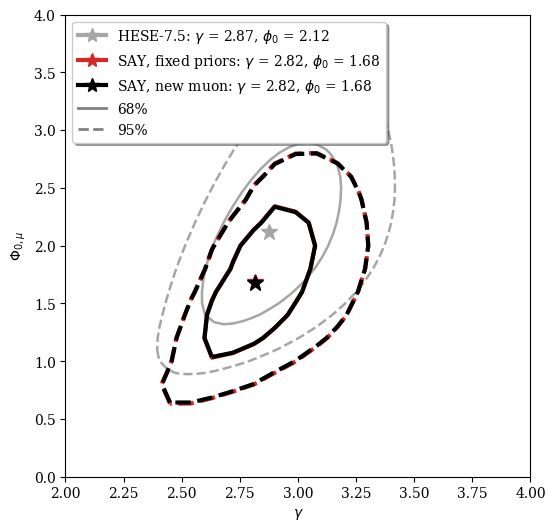

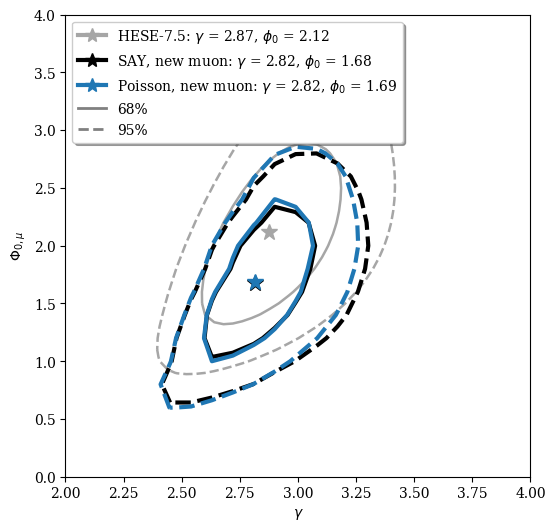

In [12]:
HESE_COLOR = "0.65"  # light grey: HESE-7.5 drawn in the background

def plot_2d(names, colors, savepath):
    lw, linestyles, our_levels = 3.0, ["-", "--"], [2.27, 5.99]  # 68%, 95% (as in fit_result_2D.ipynb)
    fig, ax = plt.subplots(1, 1)
    lh, ll = [], []
    for name, color in zip(names, colors):
        if name == "HESE-7.5":
            # previous result in the background
            color = HESE_COLOR
            ax.contour(G_hese, N_hese, Z_hese, levels=hese_levels, colors=color, linewidths=0.6 * lw, linestyles=linestyles)
            bfx, bfy = hese_bf
        else:
            x, y, dllh, bf = scans_2d[name]
            ax.contour(x, y, dllh, levels=our_levels, colors=color, linewidths=lw, linestyles=linestyles)
            bfx, bfy = bf[x_param], bf[y_param]
        ax.plot([bfx], [bfy], "*", color=color, markersize=12)
        lh.append(Line2D([0], [0], color=color, linewidth=lw, marker="*", markersize=10))
        ll.append(f"{name}: " + r"$\gamma$ = " + f"{bfx:.2f}, " + r"$\phi_0$ = " + f"{bfy:.2f}")
    lh += [Line2D([0], [0], color="grey", linestyle=ls, linewidth=2) for ls in linestyles]
    ll += ["68%", "95%"]
    ax.set_xlabel(r"$\gamma$")
    ax.set_ylabel(r"$\Phi_{0,\mu}$")
    ax.legend(lh, ll, loc="upper left", frameon=True, fancybox=True, shadow=True, fontsize=10)
    fig.savefig(savepath, bbox_inches="tight")
    fig.savefig(savepath.replace(".pdf", ".png"), bbox_inches="tight", dpi=100)
    plt.show()

plot_2d(["HESE-7.5", "SAY, fixed priors", "SAY, new muon"], [HESE_COLOR, "C3", "black"], f"{plotting_path}/contour_fixedprior_vs_newmuon.pdf")
plot_2d(["HESE-7.5", "SAY, new muon", "Poisson, new muon"], [HESE_COLOR, "black", "C0"], f"{plotting_path}/contour_newmuon_SAY_vs_Poisson.pdf")